# E2 — Implementing and comparing multi-head self-attention

Manual and PyTorch attention are compared on Fashion-MNIST using row, patch and CNN-stem tokens. AI assistance is disclosed in [AI_USE_REPORT.md](../AI_USE_REPORT.md).

## Experimental protocol

Six configurations use 30 epochs and seeds 42, 43 and 44; paired attention implementations start from identical parameters.

In [1]:
from pathlib import Path
import subprocess
import sys

colab_root = Path("/content/CO5085-deep-learning")
roots = (Path.cwd(), *Path.cwd().parents, colab_root)
ROOT = next(
    (path for path in roots if (path / "configs/experiments.json").is_file()), None
)
if ROOT is None and "google.colab" in sys.modules:
    subprocess.run(
        [
            "git",
            "clone",
            "--depth",
            "1",
            "https://github.com/dathuynh1108/CO5085-deep-learning.git",
            str(colab_root),
        ],
        check=True,
    )
    ROOT = colab_root
if ROOT is None:
    raise FileNotFoundError(
        "Open the notebook from the CO5085-deep-learning directory."
    )
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "notebooks"))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image
from IPython.display import display

from common.config import get_experiment
from common.config import load_experiments
from common.data import CLASS_NAMES
from common.data import prepare_data
from common.engine import train
from common.evaluation import evaluate_run
from common.factory import build_model
from common.factory import parameter_count
from common.runtime import atomic_csv
from common.runtime import atomic_json
from common.runtime import choose_device
from common.runtime import environment_info
from common.runtime import seed_everything
from exercise_notebook import flag
from exercise_notebook import read_json
from exercise_notebook import setting
from exercise_notebook import show_comparison
from exercise_notebook import show_figure
from exercise_notebook import show_results
from exercise_notebook import verified_training_status

EXERCISE = "E2"

In [3]:
SEEDS = tuple(int(value) for value in setting("SEEDS", "42,43,44").split(","))
MODELS = setting("MODELS")
EPOCHS = int(setting("EPOCHS")) if setting("EPOCHS") else None
DEVICE = setting("DEVICE", "auto")
WORKERS = int(setting("WORKERS", "0"))
DATA_ROOT = (ROOT / setting("DATA_ROOT", "data")).resolve()
OUTPUT_ROOT = (ROOT / setting("OUTPUT_ROOT", "runs/notebooks/exercises")).resolve()
RESUME = flag("RESUME")
DETERMINISTIC = flag("DETERMINISTIC")
DOWNLOAD = flag("DOWNLOAD", default=True)
CONFIRM_TEST = flag("CONFIRM_TEST")

In [4]:
if (
    not SEEDS
    or len(set(SEEDS)) != len(SEEDS)
    or any(not 0 <= seed < 2**32 for seed in SEEDS)
):
    raise ValueError("SEEDS must contain distinct seeds in [0, 2**32).")
SEEDS = tuple(sorted(SEEDS))
if EPOCHS is not None and OUTPUT_ROOT == (ROOT / "runs/notebooks/exercises").resolve():
    raise ValueError("Changing EPOCHS requires a separate OUTPUT_ROOT for the trial.")
if OUTPUT_ROOT.is_relative_to((ROOT / "runs" / "exercises").resolve()):
    raise ValueError(
        "Choose an OUTPUT_ROOT outside the historical results directory runs/exercises."
    )
if WORKERS < 0:
    raise ValueError("WORKERS must be a nonnegative integer.")
if CONFIRM_TEST and EPOCHS is not None:
    raise ValueError(
        "Runs with an EPOCHS override can only be evaluated on validation data."
    )
device = choose_device(DEVICE)

In [5]:
presets = load_experiments()
allowed = {row.id for row in presets if row.exercise == EXERCISE}
selected = (
    tuple(value.strip() for value in MODELS.split(","))
    if MODELS
    else tuple(row.id for row in presets if row.id in allowed)
)
if len(set(selected)) != len(selected) or set(selected) - allowed:
    raise ValueError(
        f"MODELS must contain distinct configuration IDs from: {sorted(allowed)}"
    )
configs = [get_experiment(identifier, epochs=EPOCHS) for identifier in selected]
display(
    {
        "device": str(device),
        "seed": SEEDS,
        "worker": WORKERS,
        "output_root": str(OUTPUT_ROOT),
    }
)
display(
    [
        {
            key: config.to_dict()[key]
            for key in (
                "id",
                "epochs",
                "batch_size",
                "lr",
                "tokenizer",
                "backend",
                "group",
            )
        }
        for config in configs
    ]
)

{'device': 'cpu',
 'seed': (42, 43, 44),
 'worker': 0,
 'output_root': '/Users/huynhthanhdat/Workspace/research/CO5085-deep-learning/artifacts/notebook-rerun-english/exercises-a2-runs/exercises'}

[{'id': 'e2_patches_manual',
  'epochs': 30,
  'batch_size': 256,
  'lr': 0.0003,
  'tokenizer': 'patches',
  'backend': 'manual',
  'group': 'required'},
 {'id': 'e2_patches_torch',
  'epochs': 30,
  'batch_size': 256,
  'lr': 0.0003,
  'tokenizer': 'patches',
  'backend': 'torch',
  'group': 'required'},
 {'id': 'e2_rows_manual',
  'epochs': 30,
  'batch_size': 256,
  'lr': 0.0003,
  'tokenizer': 'rows',
  'backend': 'manual',
  'group': 'required'},
 {'id': 'e2_rows_torch',
  'epochs': 30,
  'batch_size': 256,
  'lr': 0.0003,
  'tokenizer': 'rows',
  'backend': 'torch',
  'group': 'required'},
 {'id': 'e2_cnn_manual',
  'epochs': 30,
  'batch_size': 256,
  'lr': 0.0003,
  'tokenizer': 'cnn',
  'backend': 'manual',
  'group': 'required'},
 {'id': 'e2_cnn_torch',
  'epochs': 30,
  'batch_size': 256,
  'lr': 0.0003,
  'tokenizer': 'cnn',
  'backend': 'torch',
  'group': 'required'}]

## Fashion-MNIST data exploration

A stratified split provides 54,000 training and 6,000 validation images; normalization uses training statistics, and 10,000 separate test images are used for evaluation.

In [6]:
split_seeds = {config.split_seed for config in configs}
if len(split_seeds) != 1:
    raise ValueError("Comparisons require the same data split.")
train_set, validation_set, dataset = prepare_data(
    DATA_ROOT, split_seeds.pop(), DOWNLOAD
)
train_counts = np.bincount(
    train_set.labels.numpy()[train_set.indices], minlength=len(CLASS_NAMES)
)
validation_counts = np.bincount(
    validation_set.labels.numpy()[validation_set.indices], minlength=len(CLASS_NAMES)
)
display(
    {
        key: dataset[key]
        for key in ("n_train", "n_validation", "mean", "std", "fingerprint")
    }
)

{'n_train': 54000,
 'n_validation': 6000,
 'mean': 0.2858728124583167,
 'std': 0.3528899747734446,
 'fingerprint': 'd4c63c5dac60102d9ae0cd935311a9eac958b8a81b8577c047e3c2b0056dc50e'}

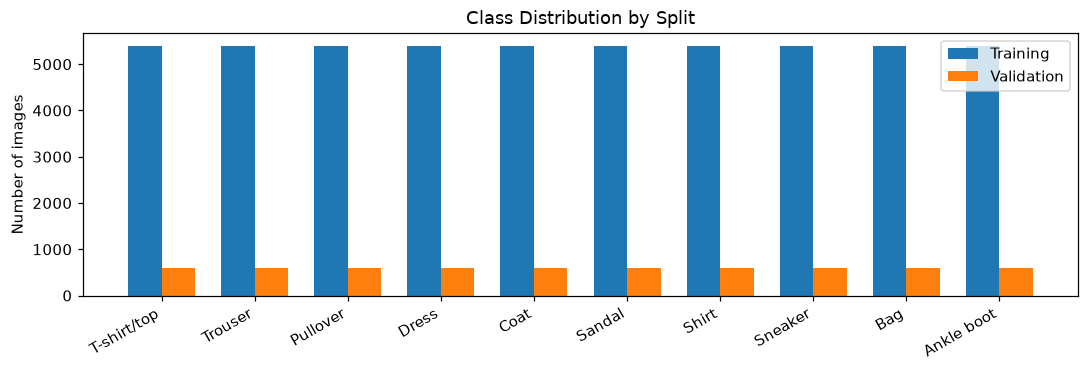

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.5))
labels = np.arange(len(CLASS_NAMES))
ax.bar(labels - 0.18, train_counts, 0.36, label="Training")
ax.bar(labels + 0.18, validation_counts, 0.36, label="Validation")
ax.set_xticks(labels, CLASS_NAMES, rotation=30, ha="right")
ax.set(ylabel="Number of images", title="Class Distribution by Split")
ax.legend()
fig.tight_layout()
show_figure(fig)

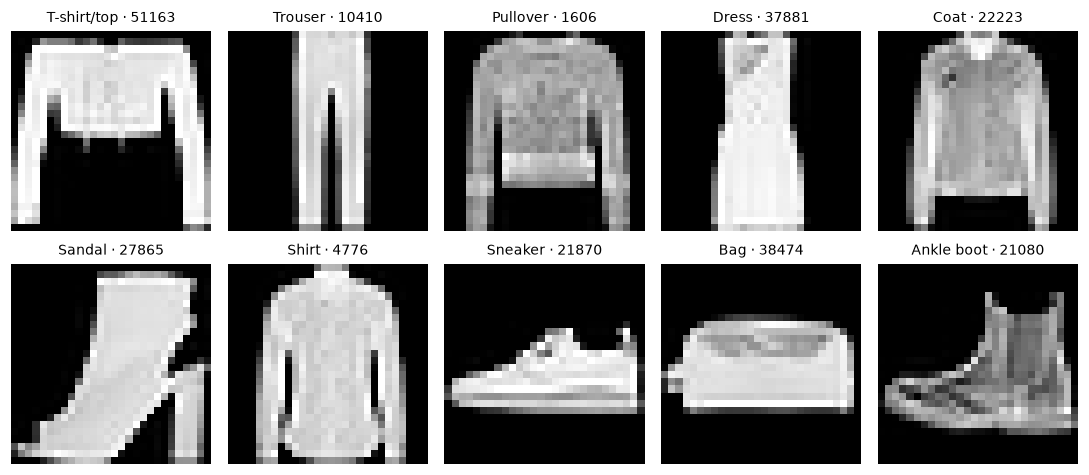

In [8]:
rng = np.random.default_rng(2026)
y = train_set.labels.numpy()
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for cls, ax in enumerate(axes.flat):
    index = int(rng.choice(train_set.indices[y[train_set.indices] == cls]))
    ax.imshow(train_set.images[index], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{CLASS_NAMES[cls]} · {index}", fontsize=9)
    ax.axis("off")
fig.tight_layout()
show_figure(fig)

## Model architecture

Two encoder blocks process image rows, 4×4 patches or spatial features from a CNN stem.

The layers and forward pass are defined in [E2/models.py](../src/E2/models.py).

In [9]:
seed_everything(SEEDS[0], DETERMINISTIC)
images = torch.stack([train_set[i][0] for i in range(4)])
model_shapes = []
with torch.inference_mode():
    for config in configs:
        model = build_model(config).eval()
        row = {
            "experiment": config.id,
            "parameters": parameter_count(model),
            "logits": list(model(images).shape),
        }
        row["token_shape"] = " × ".join(map(str, model.tokenizer(images).shape[1:]))
        model_shapes.append(row)
display(model_shapes)

[{'experiment': 'e2_patches_manual',
  'parameters': 71946,
  'logits': [4, 10],
  'token_shape': '49 × 64'},
 {'experiment': 'e2_patches_torch',
  'parameters': 71946,
  'logits': [4, 10],
  'token_shape': '49 × 64'},
 {'experiment': 'e2_rows_manual',
  'parameters': 71370,
  'logits': [4, 10],
  'token_shape': '28 × 64'},
 {'experiment': 'e2_rows_torch',
  'parameters': 71370,
  'logits': [4, 10],
  'token_shape': '28 × 64'},
 {'experiment': 'e2_cnn_manual',
  'parameters': 89770,
  'logits': [4, 10],
  'token_shape': '49 × 64'},
 {'experiment': 'e2_cnn_torch',
  'parameters': 89770,
  'logits': [4, 10],
  'token_shape': '49 × 64'}]

### Attention equivalence at identical initialization

Outputs and input gradients are compared with dropout disabled; agreement here does not imply identical training outcomes.

In [10]:
from E2.models import ManualSelfAttention
from E2.models import TorchSelfAttention

seed_everything(SEEDS[0], DETERMINISTIC)
manual = ManualSelfAttention(dim=64, heads=4).eval()
reference = TorchSelfAttention.from_manual(manual).eval()
tokens = torch.randn(2, 28, 64, requires_grad=True)
manual_output = manual(tokens)
reference_output = reference(tokens)
(manual_gradient,) = torch.autograd.grad(manual_output.square().mean(), tokens)
(reference_gradient,) = torch.autograd.grad(reference_output.square().mean(), tokens)

In [11]:
torch.testing.assert_close(manual_output, reference_output, atol=1e-6, rtol=1e-5)
torch.testing.assert_close(manual_gradient, reference_gradient, atol=1e-7, rtol=1e-5)
display(
    {
        "Maximum absolute output difference": (manual_output - reference_output)
        .abs()
        .max()
        .item(),
        "Maximum absolute input-gradient difference": (
            manual_gradient - reference_gradient
        )
        .abs()
        .max()
        .item(),
    }
)

{'Maximum absolute output difference': 1.4901161193847656e-07,
 'Maximum absolute input-gradient difference': 1.4551915228366852e-10}

## Training and checkpoint selection

Checkpoints are selected by validation accuracy, with lower cross-entropy breaking ties.

The shared [training loop](../src/common/engine.py#L54-L85) performs zero_grad → forward → cross-entropy → backward → gradient clipping → optimizer.step.

In [12]:
run_environment = environment_info(device)
directories = {}
for config in configs:
    for seed in SEEDS:
        directory = OUTPUT_ROOT / config.id / f"seed_{seed}"
        status = verified_training_status(
            directory,
            config,
            seed,
            dataset,
            WORKERS,
            DETERMINISTIC,
            run_environment,
        )
        if status == "trained":
            print(f"Reusing completed run: {config.id}, seed={seed}", flush=True)
        else:
            if status == "incomplete" and not RESUME:
                raise RuntimeError(
                    f"Incomplete run: {directory}. Enable RESUME to continue."
                )
            directory = train(
                config,
                seed,
                DATA_ROOT,
                OUTPUT_ROOT,
                device_name=DEVICE,
                workers=WORKERS,
                resume=status == "incomplete",
                deterministic=DETERMINISTIC,
                download=DOWNLOAD,
            )
        directories[(config.id, seed)] = directory

e2_patches_manual | seed=42 | cuda | parameters=71,946


  01/30: CE=1.3957 | val=67.0167% | 1.4s


  02/30: CE=0.8369 | val=74.4833% | 1.1s


  03/30: CE=0.6705 | val=78.2000% | 1.1s


  04/30: CE=0.5898 | val=80.9000% | 1.1s


  05/30: CE=0.5429 | val=81.9667% | 1.1s


... (548 outputs left out)

  27/30: CE=0.2561 | val=89.4167% | 1.0s


  28/30: CE=0.2534 | val=89.4667% | 1.0s


  29/30: CE=0.2537 | val=89.4500% | 1.0s


  30/30: CE=0.2558 | val=89.5000% | 1.0s


## Evaluation and error analysis

Paired runs compare accuracy and training time for each tokenizer.

In [13]:
split = "test" if CONFIRM_TEST else "validation"
report_dir = (
    OUTPUT_ROOT
    / "notebook_analysis"
    / EXERCISE
    / ("seeds_" + "_".join(map(str, SEEDS)))
    / split
)
evaluations, results = {}, []
for (identifier, seed), directory in directories.items():
    result = evaluate_run(
        directory,
        DATA_ROOT,
        split=split,
        confirm_test=CONFIRM_TEST,
        device_name=DEVICE,
        workers=WORKERS,
        download=DOWNLOAD,
    )
    evaluations[(identifier, seed)] = result
    training = read_json(directory / "metrics.json")
    results.append(
        {
            "experiment": identifier,
            "seed": seed,
            "split": split,
            "best_epoch": result["best_epoch"],
            "accuracy": result["accuracy"],
            "macro_f1": result["macro_f1"],
            "cross_entropy": result["cross_entropy"],
            "n_parameters": training["n_parameters"],
            "median_train_seconds": training["median_train_seconds"],
            "total_train_seconds": training["total_train_seconds"],
            "inference_images_per_second": result["inference_images_per_second"],
            "signature": result["signature"],
            "model_sha256": result["model_sha256"],
        }
    )

seed_42 test: accuracy=85.3200%, macro-F1=0.8524


seed_43 test: accuracy=85.9500%, macro-F1=0.8596


seed_44 test: accuracy=86.5100%, macro-F1=0.8650


seed_42 test: accuracy=85.6400%, macro-F1=0.8562


seed_43 test: accuracy=86.0600%, macro-F1=0.8605


seed_44 test: accuracy=86.3700%, macro-F1=0.8636


... (8 outputs left out)

seed_44 test: accuracy=88.6500%, macro-F1=0.8865


seed_42 test: accuracy=88.0900%, macro-F1=0.8809


seed_43 test: accuracy=88.5400%, macro-F1=0.8852


seed_44 test: accuracy=88.8700%, macro-F1=0.8883


In [14]:
atomic_csv(report_dir / "results.csv", results)
atomic_json(
    report_dir / "protocol.json",
    {
        "notebook": f"{EXERCISE}.ipynb",
        "configurations": [config.to_dict() for config in configs],
        "seeds": list(SEEDS),
        "dataset": dataset,
        "device": str(device),
        "workers": WORKERS,
        "deterministic": DETERMINISTIC,
        "split": split,
        "confirm_test": CONFIRM_TEST,
    },
)
show_results(results)

| Configuration | Seed | Parameters | Accuracy mean ± SD (%) | Macro-F1 mean ± SD | Median training seconds/epoch |
| --- | --- | ---: | ---: | ---: | ---: |
| e2_patches_manual | 42, 43, 44 | 71,946 | 85.927 ± 0.595 | 0.859 ± 0.006 | 1.10 |
| e2_patches_torch | 42, 43, 44 | 71,946 | 86.023 ± 0.366 | 0.860 ± 0.004 | 1.05 |
| e2_rows_manual | 42, 43, 44 | 71,370 | 87.920 ± 0.026 | 0.879 ± 0.000 | 0.99 |
| e2_rows_torch | 42, 43, 44 | 71,370 | 87.863 ± 0.015 | 0.878 ± 0.000 | 0.94 |
| e2_cnn_manual | 42, 43, 44 | 89,770 | 88.587 ± 0.339 | 0.886 ± 0.003 | 1.02 |
| e2_cnn_torch | 42, 43, 44 | 89,770 | 88.500 ± 0.392 | 0.885 ± 0.004 | 0.96 |

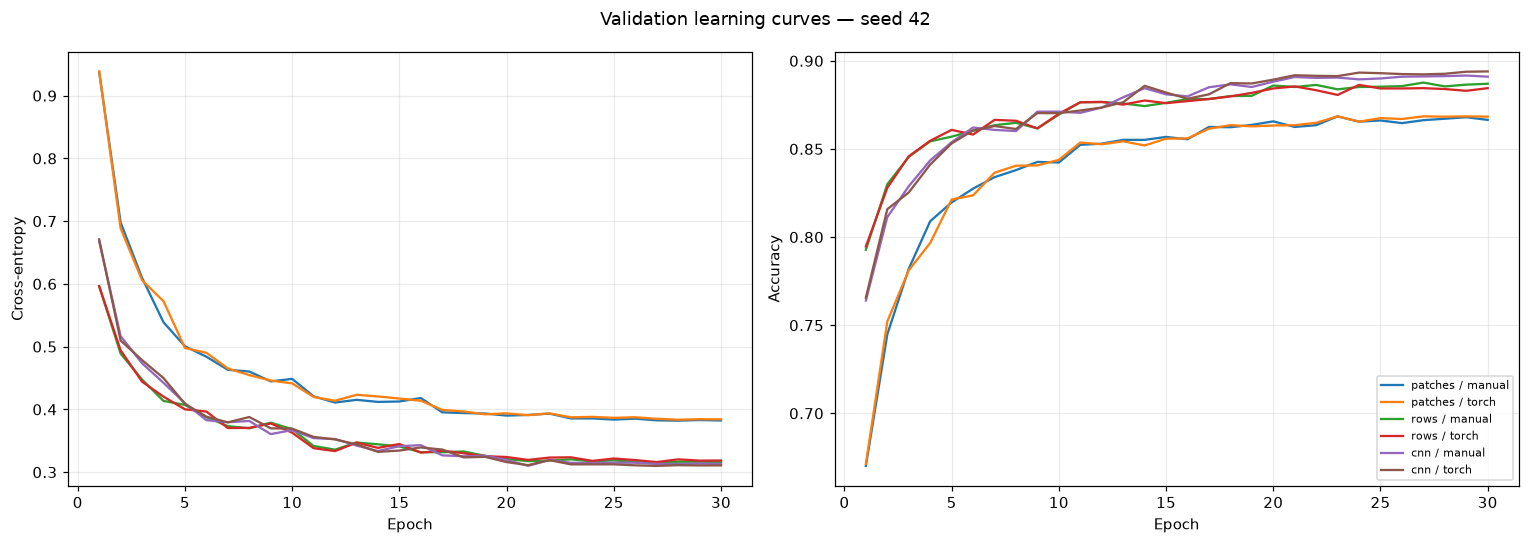

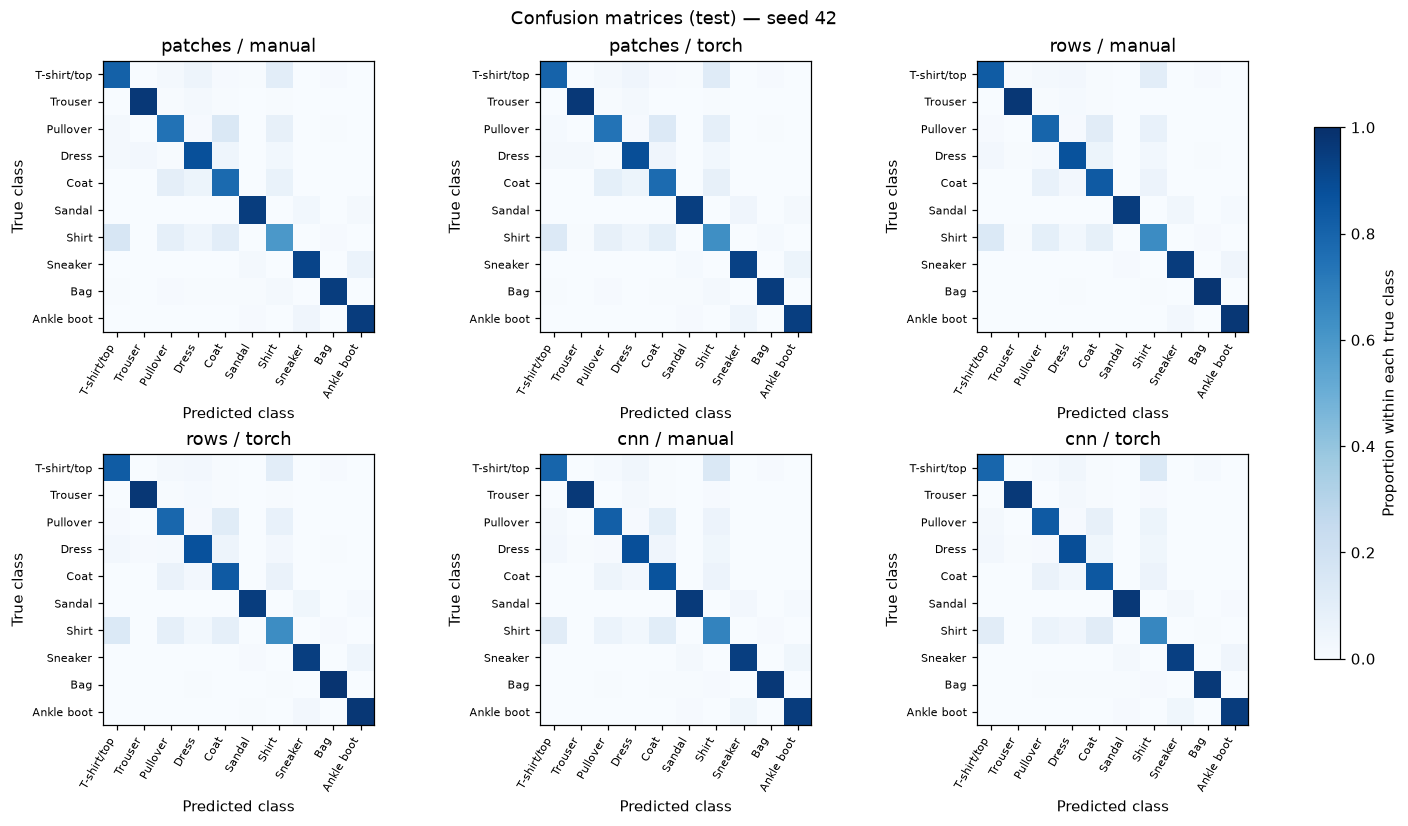

In [15]:
representative_seed = min(SEEDS)
show_comparison(configs, directories, evaluations, representative_seed, report_dir)

High-confidence misclassifications: e2_patches_manual, seed=42


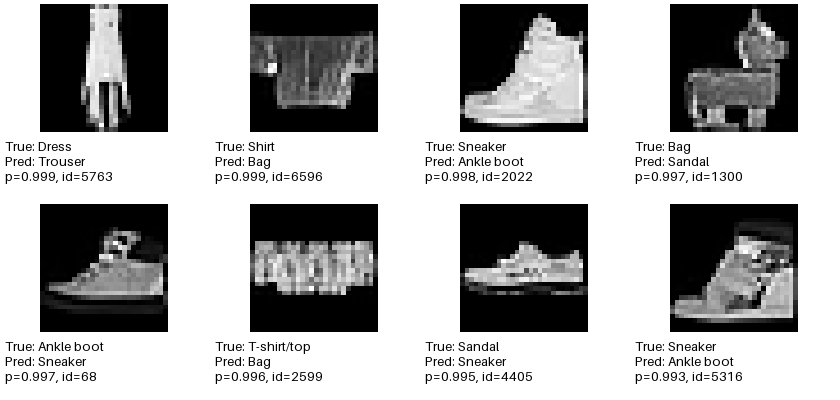

In [16]:
reference = configs[0].id
examples = (
    directories[(reference, representative_seed)] / "plots" / f"mistakes_{split}.png"
)
if examples.is_file():
    print(
        f"High-confidence misclassifications: {reference}, seed={representative_seed}"
    )
    display(Image(filename=str(examples), width=650))

## Comparison limits

CNN-stem tokens add learned local features and parameters, so tokenizer differences cannot be attributed to sequence length alone.